# 02 - The zoom audit: do metric depth models respect a digital zoom?

Results come from `scripts/run_audit.py`, run on a Kaggle GPU (kernel
`zoom-equivariance-audit`), 200 images per set, centre zooms s = 1, 1.25, 1.5, 2, 3.

Per image we fit two exponents (see `src/analysis.py`):
- **alpha**: depth of the same pixels scales like s^-alpha. Ideal 0. A model that only
  reads apparent size gives 1 (twice as big = twice as close).
- **beta**: predicted focal scales like s^beta. Ideal 1.

Control: the *blur* row degrades the image like a 2x zoom without changing the field
of view. If depth moved as much under blur, interpolation would be the explanation.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import analysis as A

FIG, TAB = ROOT / "outputs/figures", ROOT / "outputs/tables"
TAB.mkdir(parents=True, exist_ok=True)
MAIN = ["dav2-s", "dav2-b", "zoedepth", "depthpro", "moge2-s", "unidepth2-s", "metric3d-s", "metric3d-s-staleK"]

df = A.load()
df = df[df.model.isin(MAIN)]
MAIN = [m for m in MAIN if m in set(df.model)]  # models whose runs are in
print(df.groupby(["model", "dataset"]).name.nunique().unstack())

dataset            diode-in  diode-out  kitti  nyu
model                                             
dav2-b                  200        200    200  200
dav2-s                  200        200    200  200
metric3d-s              200        200    200  200
metric3d-s-staleK       200        200    200  200
moge2-s                 200        200    200  200
unidepth2-s             200        200    200  200
zoedepth                200        200    200  200


In [2]:
pi = A.per_image(df)
summ = A.summary(pi).merge(A.blur_control(df).reset_index(), on=["model", "dataset"], how="left")
summ.to_csv(TAB / "audit_by_model_dataset.csv", index=False)
cols = ["model", "dataset", "n", "alpha", "alpha_lo", "alpha_hi", "beta", "die2", "blur2", "absrel1", "absrel2", "absrel3"]
summ[cols].round(3)

/home/rabeya-noor/Code/zoom-equivariance/src/analysis.py:99: RuntimeWarning: Mean of empty slice
  base2=np.nanmean(g.base2), base3=np.nanmean(g.base3),
/home/rabeya-noor/Code/zoom-equivariance/src/analysis.py:101: RuntimeWarning: All-NaN slice encountered
  fx_err1=np.nanmedian(g.fx_err1)))


,model,dataset,n,alpha,alpha_lo,alpha_hi,beta,die2,blur2,absrel1,absrel2,absrel3
0,dav2-b,diode-in,200,0.754,0.686,0.788,NaN,0.499,0.009,0.236,0.463,0.584
1,dav2-b,diode-out,200,0.662,0.624,0.695,NaN,0.436,0.007,0.681,0.556,0.564
2,dav2-b,kitti,200,1.188,1.129,1.262,NaN,0.644,0.012,0.115,0.489,0.736
3,dav2-b,nyu,200,0.830,0.809,0.870,NaN,0.588,0.006,0.219,0.339,0.512
4,dav2-s,diode-in,200,0.760,0.718,0.802,NaN,0.497,0.014,0.266,0.472,0.623
5,dav2-s,diode-out,200,0.707,0.681,0.744,NaN,0.458,0.012,0.653,0.542,0.576
6,dav2-s,kitti,200,1.277,1.196,1.332,NaN,0.646,0.013,0.133,0.525,0.762
7,dav2-s,nyu,200,1.071,1.029,1.135,NaN,0.685,0.010,0.216,0.417,0.646
8,metric3d-s,diode-in,200,-0.088,-0.158,-0.047,NaN,0.165,0.031,0.133,0.291,0.477
9,metric3d-s,diode-out,200,-0.182,-0.213,-0.146,NaN,0.122,0.016,0.276,0.424,0.617


## Table 1: pooled over the four sets

In [3]:
pooled = A.summary(pi, by=("model",)).set_index("model").loc[MAIN]
blur = A.blur_control(df).groupby("model").mean()
pooled["blur2"] = blur
pooled["absrel_ratio_3"] = pooled.absrel3 / pooled.absrel1
t1 = pooled[["alpha", "alpha_lo", "alpha_hi", "beta", "die2", "blur2", "absrel1", "absrel2", "absrel3", "absrel_ratio_3"]]
t1.index = [A.PRETTY[m] for m in t1.index]
t1.round(3).to_csv(TAB / "table1_pooled.csv")
t1.round(3)

/home/rabeya-noor/Code/zoom-equivariance/src/analysis.py:99: RuntimeWarning: Mean of empty slice
  base2=np.nanmean(g.base2), base3=np.nanmean(g.base3),
/home/rabeya-noor/Code/zoom-equivariance/src/analysis.py:101: RuntimeWarning: All-NaN slice encountered
  fx_err1=np.nanmedian(g.fx_err1)))


,alpha,alpha_lo,alpha_hi,beta,die2,blur2,absrel1,absrel2,absrel3,absrel_ratio_3
DA-V2-S,0.954,0.925,0.990,NaN,0.608,0.013,0.317,0.489,0.652,2.057
DA-V2-B,0.852,0.820,0.874,NaN,0.579,0.008,0.313,0.462,0.599,1.914
ZoeDepth,0.614,0.582,0.639,NaN,0.438,0.007,0.310,0.434,0.539,1.737
MoGe-2-S,0.363,0.337,0.382,0.558,0.244,0.031,0.274,0.384,0.465,1.697
UniDepthV2-S,0.343,0.299,0.395,0.447,0.264,0.040,0.824,0.840,0.792,0.960
Metric3D v2-S,-0.073,-0.083,-0.063,NaN,0.074,0.016,0.142,0.234,0.358,2.517
Metric3D v2-S (stale K),0.927,0.917,0.937,NaN,0.641,0.016,0.142,0.488,0.628,4.415


## Figure 2: how depth and focal move with zoom

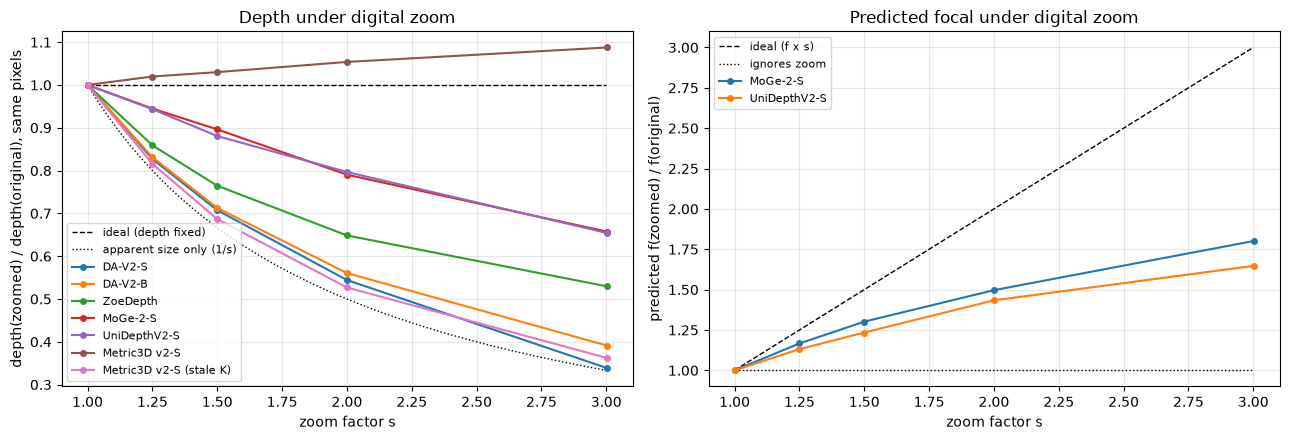

In [4]:
z = df[df.kind == "zoom"].copy()
z["log_fx"] = np.log(z.fx / z.fx_base)
curve = z.groupby(["model", "zoom"]).agg(depth=("log_ratio_self", "median"), focal=("log_fx", "median"),
                                         s=("s_true", "median")).reset_index()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
ss = np.linspace(1, 3, 50)
a1.plot(ss, np.ones_like(ss), "k--", lw=1, label="ideal (depth fixed)")
a1.plot(ss, 1 / ss, "k:", lw=1, label="apparent size only (1/s)")
a2.plot(ss, ss, "k--", lw=1, label="ideal (f x s)")
a2.plot(ss, np.ones_like(ss), "k:", lw=1, label="ignores zoom")
for m in MAIN:
    c = curve[curve.model == m].sort_values("zoom")
    a1.plot(c.s, np.exp(c.depth), "o-", ms=4, label=A.PRETTY[m])
    if c.focal.notna().all():
        a2.plot(c.s, np.exp(c.focal), "o-", ms=4, label=A.PRETTY[m])
a1.set(xlabel="zoom factor s", ylabel="depth(zoomed) / depth(original), same pixels", title="Depth under digital zoom")
a2.set(xlabel="zoom factor s", ylabel="predicted f(zoomed) / f(original)", title="Predicted focal under digital zoom")
for a in (a1, a2):
    a.grid(alpha=0.3)
    a.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "02_depth_and_focal_vs_zoom.png", dpi=110)
plt.show()

## Per-dataset alpha (with 95% bootstrap CI)

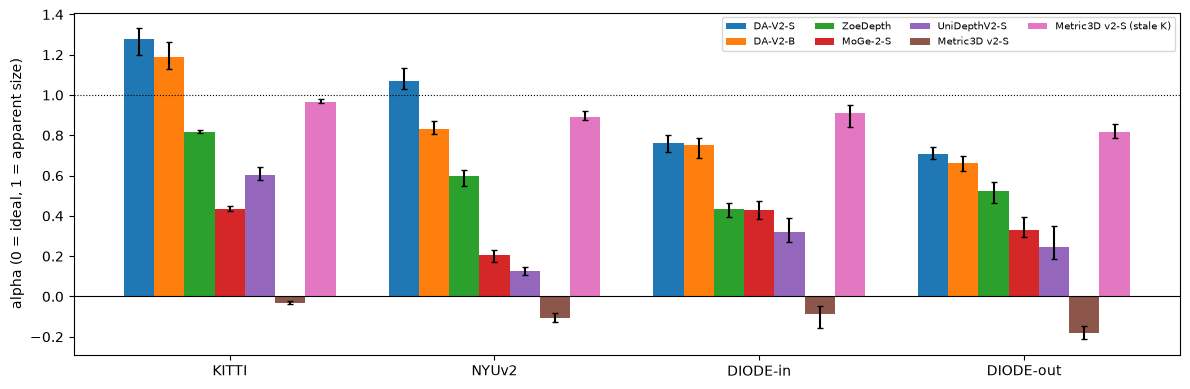

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
width = 0.8 / len(MAIN)
for k, m in enumerate(MAIN):
    s = summ[summ.model == m].set_index("dataset").reindex(A.DATASETS)
    x = np.arange(len(A.DATASETS)) + k * width
    ax.bar(x, s.alpha, width, yerr=[s.alpha - s.alpha_lo, s.alpha_hi - s.alpha], label=A.PRETTY[m], capsize=2)
ax.axhline(0, color="k", lw=0.8)
ax.axhline(1, color="k", ls=":", lw=0.8)
ax.set_xticks(np.arange(len(A.DATASETS)) + 0.4 - width / 2, [A.PRETTY_DS[d] for d in A.DATASETS])
ax.set_ylabel("alpha (0 = ideal, 1 = apparent size)")
ax.legend(fontsize=7, ncol=4)
plt.tight_layout()
plt.savefig(FIG / "02_alpha_per_dataset.png", dpi=110)
plt.show()

## What does a 2x zoom cost in accuracy?

In [6]:
acc = summ.pivot(index="model", columns="dataset", values=["absrel1", "absrel2", "absrel3"]).loc[MAIN]
acc.round(3)

absrel1                          absrel2                   \
dataset           diode-in diode-out  kitti    nyu diode-in diode-out  kitti   
model                                                                          
dav2-s               0.266     0.653  0.133  0.216    0.472     0.542  0.525   
dav2-b               0.236     0.681  0.115  0.219    0.463     0.556  0.489   
zoedepth             0.308     0.600  0.196  0.136    0.437     0.632  0.367   
moge2-s              0.257     0.450  0.270  0.120    0.407     0.481  0.448   
unidepth2-s          0.245     2.749  0.189  0.114    0.354     2.610  0.245   
metric3d-s           0.133     0.276  0.068  0.093    0.291     0.424  0.077   
metric3d-s-staleK    0.133     0.276  0.068  0.093    0.461     0.495  0.508   

                          absrel3                          
dataset              nyu diode-in diode-out  kitti    nyu  
model                                                      
dav2-s             0.417    0.623     0.576  0.762  0.646  
dav2-b             0.339    0.584     0.564  0.736  0.512  
zoedepth           0.299    0.490     0.685  0.574  0.406  
moge2-s            0.199    0.505     0.515  0.537  0.305  
unidepth2-s        0.152    0.502     2.053  0.409  0.209  
metric3d-s         0.143    0.477     0.617  0.093  0.246  
metric3d-s-staleK  0.487    0.596     0.621  0.667  0.628